# 03 · The forecast model and the decision it supports
**BADIR stage: Insights → Recommendations**

> **At a glance**
> * **Decision:** how many liters of each spirits family ABD should plan for each county next month.
> * **Model:** an ensemble = 0.55 × gradient-boosted trees (XGBoost, Tweedie loss) + 0.45 × "same month last year,
>   adjusted for order days".
> * **Result on four months it never saw (Jul–Oct 2026):** planning error **13.8% vs 17.3%** for today's rule at county
>   level (−20%), **5.2% vs 7.0%** at state level (−27%), bias **+2%** vs +6.5%.
> * **Worth:** ~25% less safety stock in the warehouse, and an end to systematic over-buying.

**Contents**
1. Framing: unit, horizon, metric, split
2. Feature engineering (with a worked example)
3. The algorithms we compared
4. Model selection on validation data
5. Hyperparameter tuning
6. The out-of-time test
7. Prediction intervals (calibration)
8. Business value
9. From forecast to order quantity (newsvendor)
10. Surprise scenarios

The heavy training (about 8 minutes) runs in `scripts/03_train_forecast.py` and is logged to MLflow; this notebook
reads its saved results and explains them.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from abd_demand import config as C, plotting as P, forecast as Fc

P.use_style()
pd.set_option("display.width", 170)
pd.set_option("display.float_format", "{:,.3f}".format)

TABLES = C.ROOT / "reports" / "tables"
comparison  = pd.read_csv(TABLES / "model_comparison.csv")            # every model on validation and test
hpo         = pd.read_csv(TABLES / "hpo_trials.csv")                  # the 20 tuning trials
predictions = pd.read_parquet(TABLES / "test_predictions.parquet")    # one row per store x family x test month
meta = json.loads((C.MODELS / "xgb_tweedie_final.meta.json").read_text())   # the model card
print(f"{len(meta['features'])} features | ensemble weight on XGBoost = {meta['weight']} | dropped as sensitive: {meta['dropped_sensitive']}")

38 features | ensemble weight on XGBoost = 0.55 | dropped as sensitive: ['cty_pct_hispanic']


## 1. Framing

| Choice | What we chose | Why |
|---|---|---|
| **Unit** | store × spirits family × month, added up to county and state | ABD delivers to stores, plans trucks by region and buys statewide: one bottom-up model serves all three |
| **Horizon** | one month ahead, using only data to the end of the previous month | matches ABD's buying cycle; nothing from the future leaks in |
| **Status quo** | same month last year ("seasonal naive") | the simple rule a planner uses today |
| **Metric** | **WAPE** = Σ \|actual − forecast\| ÷ Σ actual | reads as "% of liters mis-planned"; big series count more; works with zero months (MAPE divides by zero) |
| **Second metric** | **bias** = Σ (forecast − actual) ÷ Σ actual | + means over-buying (dead stock), − means under-buying (stock-outs) |

**Why a time-ordered split?** If we shuffled months randomly, the model would train on October and be tested on
September: it would see the future. Instead:

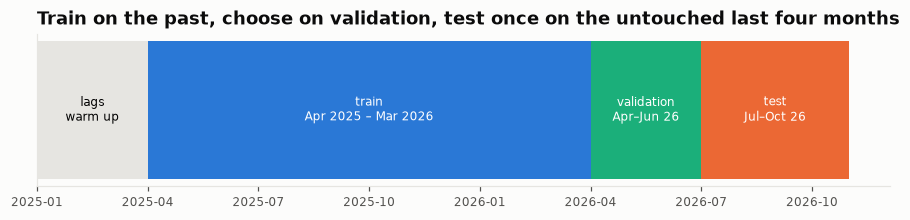

In [2]:
splits = [("train\nApr 2025 – Mar 2026", "2025-04", "2026-03", P.BLUE),
          ("validation\nApr–Jun 26", "2026-04", "2026-06", P.AQUA),
          ("test\nJul–Oct 26", "2026-07", "2026-10", P.ORANGE)]
months = pd.period_range("2025-01", "2026-10", freq="M")
fig, ax = plt.subplots(figsize=(10, 1.8))
for name, start, end, color in splits:
    a, b = months.get_loc(pd.Period(start)), months.get_loc(pd.Period(end))
    ax.barh(0, b - a + 1, left=a, color=color, height=0.5)
    ax.text(a + (b - a + 1) / 2, 0, name, ha="center", va="center", color="white", fontsize=8)
ax.barh(0, 3, left=0, color=P.GRID, height=0.5); ax.text(1.5, 0, "lags\nwarm up", ha="center", va="center", fontsize=8)
ax.set_yticks([]); ax.set_xticks(range(0, len(months), 3), [str(m) for m in months[::3]], fontsize=8); ax.grid(False)
ax.set_title("Train on the past, choose on validation, test once on the untouched last four months")
plt.show()

## 2. Feature engineering
A feature is a number the model can use to predict next month. **Every feature for month *t* uses only information
available at the end of month *t − 1*** (no leakage).

| Group | Features | Why |
|---|---|---|
| Own history | last month (`lag1`), 2, 3, 6 and 12 months ago; 3- and 6-month averages; volatility | demand is persistent |
| Store context | the store's total volume, the family's share of the store, store age, store type | a Casey's and a Costco behave differently |
| **Order calendar** | how many of the store's usual order days fall in the month; lags rescaled to it | the median store orders on one weekday: 4 vs 5 order days is a 25% swing (notebook 01) |
| Competition (from H3) | active stores in the city; new entrants in the last 3 months | new stores take volume from incumbents |
| Market (from H1/H2) | Missouri border, tax gap, population, income, education, age, density | level differences between counties |
| Statewide | the family's statewide volume last month and its year-over-year trend | the market is shrinking ~3% |

**A worked example.** One real series (a large store's vodka), showing how the history becomes features:

In [3]:
panel = pd.read_parquet(C.STORE_PANEL, columns=["store_no", "family", "month", "y", "lag1", "lag12",
                                                   "roll3_mean", "order_days", "lag12_cal_adj"])
biggest = panel[panel.family == "vodka"].groupby("store_no").y.sum().idxmax()
example = panel[(panel.store_no == biggest) & (panel.family == "vodka")].set_index("month")
example = example[["y", "lag1", "lag12", "roll3_mean", "order_days", "lag12_cal_adj"]].rename(columns={
    "y": "actual liters (target)", "lag1": "last month", "lag12": "same month last year",
    "roll3_mean": "3-month average", "order_days": "order days this month", "lag12_cal_adj": "last year, day-adjusted"})
example.tail(8).style.format("{:,.0f}", na_rep="(forecast)")

,actual liters (target),last month,same month last year,3-month average,order days this month,"last year, day-adjusted"
month,,,,,,
2026-04,"20,890","11,204","24,085","15,283",5,"26,769"
2026-05,"11,394","20,890","13,470","13,713",4,"12,056"
2026-06,"16,375","11,394","16,196","14,496",4,"16,303"
2026-07,"28,117","16,375","24,476","16,220",5,"24,413"
2026-08,"10,310","28,117","10,380","18,629",4,"11,413"
2026-09,"9,154","10,310","10,407","18,267",4,"9,441"
2026-10,"27,179","9,154","24,834","15,860",5,"24,736"
2026-11,(forecast),"27,179","10,354","15,548",4,"11,437"


Read across a row: to predict the *actual liters* the model sees last month, the same month last year, the recent
average and how many order days the month has. Notice that the big months (April, July, October) are the ones with
**5 order days** instead of 4: the calendar effect from notebook 01, visible in a single store. The last row is
November 2026, the month being forecast, so its actual is not known yet. "Last year, day-adjusted" rescales last year's value by the ratio of
order days, which is exactly the seasonal half of the final ensemble.

## 3. The algorithms we compared (in plain words)

| Model | How it works | Strength | Weakness |
|---|---|---|---|
| **Naive: last month** | next month = this month | trivial | ignores seasons |
| **Seasonal naive (status quo)** | next month = same month last year | captures seasons | carries last year's level into a shrinking market → over-buys |
| **3-month moving average** | average of the last 3 months | smooths noise | lags turning points |
| **Ridge regression** | a straight-line (linear) model on log volumes, with a penalty that shrinks coefficients to avoid over-fitting | simple, explainable | cannot capture interactions ("big store AND December") |
| **Random forest** | hundreds of decision trees, each trained on a random sample; their answers are averaged | handles interactions, robust | slower; cannot predict beyond what it has seen |
| **Gradient boosting (XGBoost)** | trees built one after another, each one correcting the errors of the ones before | usually the most accurate on tabular data | needs care (tuning, early stopping) |
| **Tweedie loss** | the error function XGBoost minimises, designed for non-negative data with many zeros and a long right tail | fits monthly liters exactly | — |
| **Ensemble** | a weighted average of two models | cancels errors that point in opposite directions | one more choice (the weight) |

**Why Tweedie?** Monthly liters per store-family are never negative, are often zero (a store skips gin one month),
and are hugely skewed (notebook 01). Ordinary least squares assumes symmetric errors; least squares on log(liters)
predicts a *geometric* mean, which systematically under-predicts totals. Tweedie is built for exactly this shape.

**Early stopping.** XGBoost adds trees until the validation error stops improving for 100 rounds, then keeps the best
number. That prevents over-fitting without guessing the number of trees.

## 4. Model selection on validation (Apr–Jun 2026)

In [4]:
valid = comparison[comparison.split == "valid"].copy()
shown = valid[valid.kind.isin(["baseline", "candidate", "candidate_ensemble"])]
table = shown[["model", "kind", "wape_county", "wape_state", "wape_store", "bias"]].sort_values("wape_county")
table.rename(columns={"wape_county": "WAPE county", "wape_state": "WAPE state", "wape_store": "WAPE store"}).reset_index(drop=True)

,model,kind,WAPE county,WAPE state,WAPE store,bias
0,xgb_tweedie+seasonal (w=0.6),candidate_ensemble,0.143,0.076,0.365,-0.025
1,random_forest+seasonal (w=0.6),candidate_ensemble,0.143,0.073,0.369,-0.015
2,xgb_squared_log+seasonal (w=0.35),candidate_ensemble,0.147,0.069,0.394,-0.027
3,ridge_log+seasonal (w=0.35),candidate_ensemble,0.147,0.061,0.392,-0.017
4,random_forest,candidate,0.157,0.101,0.358,-0.076
5,xgb_tweedie,candidate,0.164,0.118,0.354,-0.094
6,moving_avg_3m,baseline,0.172,0.088,0.398,-0.061
7,seasonal_naive_last_year,baseline,0.178,0.088,0.468,0.076
8,seasonal_naive_calendar_adj,baseline,0.183,0.103,0.462,0.077
9,naive_last_month,baseline,0.218,0.115,0.495,-0.012


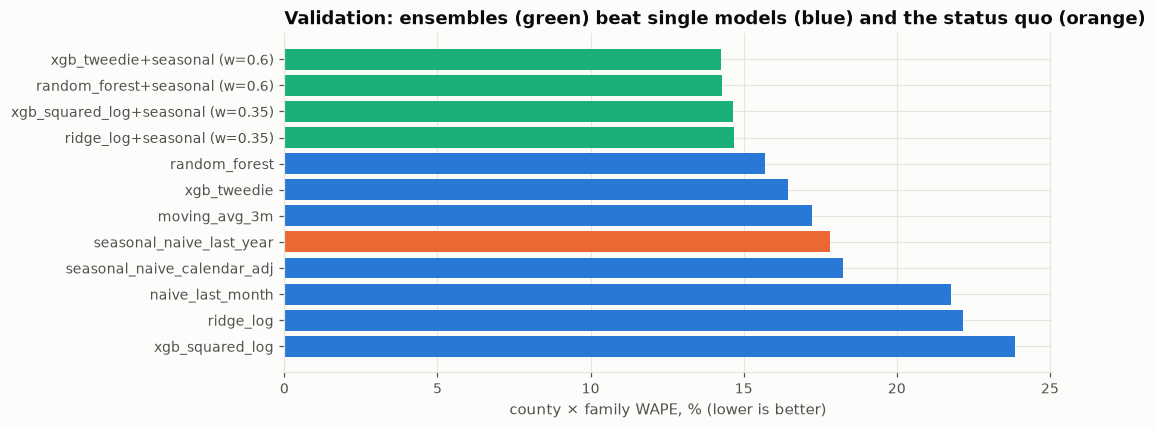

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
plot = table.sort_values("wape_county", ascending=False)
colors = [P.ORANGE if m == "seasonal_naive_last_year" else P.AQUA if "+" in m else P.BLUE for m in plot.model]
ax.barh(plot.model, 100 * plot.wape_county, color=colors)
ax.set_xlabel("county × family WAPE, % (lower is better)")
ax.set_title("Validation: ensembles (green) beat single models (blue) and the status quo (orange)")
plt.show()

**Why an ensemble?** Look at the bias column. On their own the learned models **under-forecast** (−8% to −22%):
with only 22 months of data they have seen **one** seasonal cycle, and trees cannot extrapolate above the largest
values they learned, so the giant stores get pulled down. The seasonal naive **over-forecasts** (+7.6%) because it
copies last year's level into a shrinking market. The two errors point in **opposite directions**, so averaging them
cancels part of both. The weight (0.55 on XGBoost) is the one with the lowest county WAPE whose bias stays within ±3%.

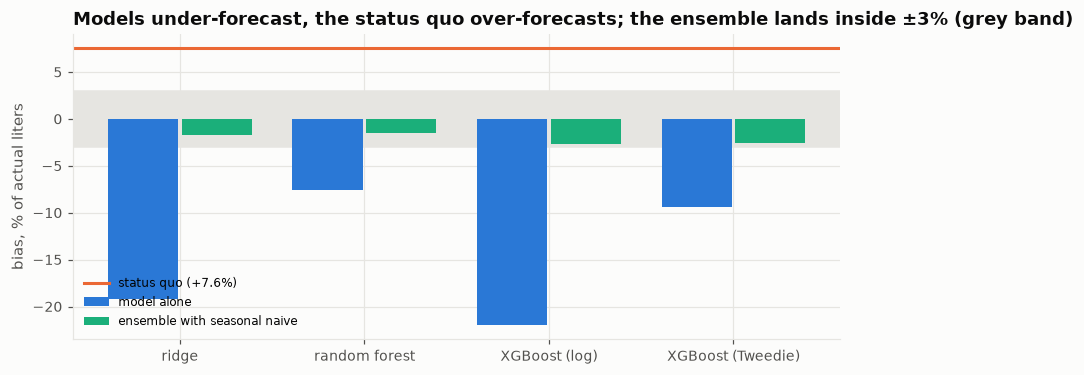

In [6]:
alone = valid[valid.kind == "candidate"].set_index("model")
ensembles = valid[valid.kind == "candidate_ensemble"].copy()
ensembles["base"] = ensembles.model.str.split("+").str[0]
ensembles = ensembles.set_index("base")
names = ["ridge_log", "random_forest", "xgb_squared_log", "xgb_tweedie"]
status_quo_bias = valid.loc[valid.model == "seasonal_naive_last_year", "bias"].iloc[0]

x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, 100 * alone.loc[names, "bias"], 0.38, color=P.BLUE, label="model alone")
ax.bar(x + 0.2, 100 * ensembles.loc[names, "bias"], 0.38, color=P.AQUA, label="ensemble with seasonal naive")
ax.axhline(100 * status_quo_bias, color=P.ORANGE, lw=2, label=f"status quo (+{100 * status_quo_bias:.1f}%)")
ax.axhspan(-3, 3, color=P.GRID, zorder=0)
ax.set_xticks(x, ["ridge", "random forest", "XGBoost (log)", "XGBoost (Tweedie)"])
ax.set_ylabel("bias, % of actual liters"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Models under-forecast, the status quo over-forecasts; the ensemble lands inside ±3% (grey band)")
P.save(fig, "fc_bias_validation"); plt.show()

## 5. Hyperparameter tuning
> **Technique card — random search.** Hyperparameters are settings chosen *before* training (tree depth, learning rate,
> etc.). Random search tries 20 random combinations and keeps the best on validation. It is usually as good as a full
> grid search at a fraction of the cost. Each trial is logged to MLflow.

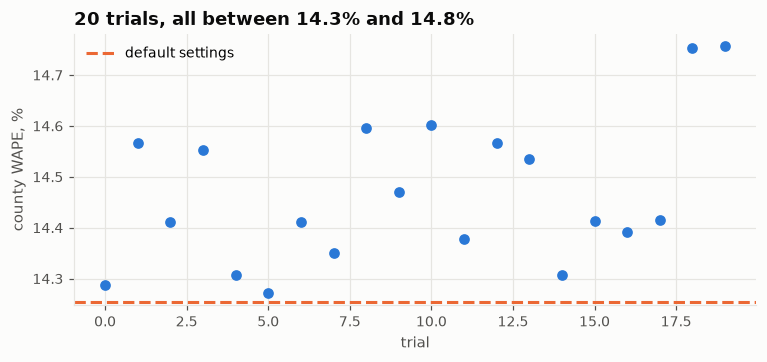

,trial,max_depth,learning_rate,min_child_weight,subsample,tweedie_variance_power,wape_county,bias
0,5,6,0.020,5,0.600,1.400,0.143,-0.018
1,0,10,0.020,1,0.900,1.100,0.143,-0.028
2,4,4,0.050,20,1.000,1.300,0.143,-0.020


In [7]:
default_wape = valid.loc[valid.model.str.startswith("xgb_tweedie+"), "wape_county"].iloc[0]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(hpo.trial, 100 * hpo.wape_county, color=P.BLUE)
ax.axhline(100 * default_wape, color=P.ORANGE, ls="--", label="default settings")
ax.set_xlabel("trial"); ax.set_ylabel("county WAPE, %"); ax.legend()
ax.set_title(f"20 trials, all between {100 * hpo.wape_county.min():.1f}% and {100 * hpo.wape_county.max():.1f}%")
plt.show()
hpo.sort_values("wape_county").head(3)[["trial", "max_depth", "learning_rate", "min_child_weight",
                                        "subsample", "tweedie_variance_power", "wape_county", "bias"]]

**Honest result.** Tuning barely matters: every trial lands within half a percentage point, and the defaults are
about as good. The gains come from **features and the ensemble design**. Under a reduced budget, this step can be skipped.

## 6. The out-of-time test (Jul–Oct 2026, used once)

In [8]:
models = {
    "status quo: same month last year": "p_seasonal_naive_last_year",
    "seasonal naive, day-adjusted":     "p_seasonal_naive_calendar_adj",
    "naive: last month":                "p_naive_last_month",
    "3-month moving average":           "p_moving_avg_3m",
    "ridge":                            "p_ridge",
    "random forest":                    "p_rf",
    "tuned XGBoost alone":              "p_xgb",
    "FINAL ensemble":                   "p_final",
}
test_table = pd.DataFrame({name: Fc.evaluate(predictions, col) for name, col in models.items()}).T
test_table = test_table[["wape_county", "wape_state", "wape_store", "bias"]]
status_quo = test_table.loc["status quo: same month last year"]
test_table["county error vs status quo"] = (test_table.wape_county / status_quo.wape_county - 1).map("{:+.0%}".format)
test_table.to_csv(TABLES / "test_results.csv")
test_table

,wape_county,wape_state,wape_store,bias,county error vs status quo
status quo: same month last year,0.173,0.070,0.485,0.065,+0%
"seasonal naive, day-adjusted",0.165,0.060,0.477,0.055,-5%
naive: last month,0.227,0.113,0.504,-0.020,+31%
3-month moving average,0.181,0.094,0.416,-0.008,+5%
ridge,0.184,0.106,0.417,-0.025,+7%
random forest,0.151,0.081,0.369,-0.020,-13%
tuned XGBoost alone,0.146,0.068,0.366,-0.009,-16%
FINAL ensemble,0.138,0.051,0.390,0.020,-20%


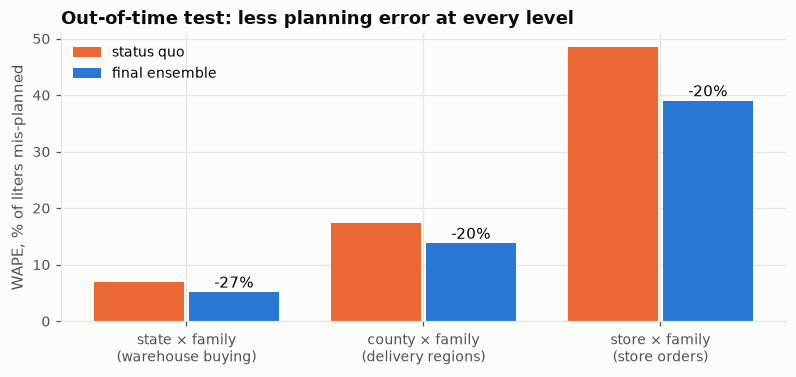

In [9]:
levels = ["wape_state", "wape_county", "wape_store"]
labels = ["state × family\n(warehouse buying)", "county × family\n(delivery regions)", "store × family\n(store orders)"]
final = test_table.loc["FINAL ensemble", levels].astype(float)
current = status_quo[levels].astype(float)

x = np.arange(3)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.bar(x - 0.2, 100 * current, 0.38, color=P.ORANGE, label="status quo")
ax.bar(x + 0.2, 100 * final, 0.38, color=P.BLUE, label="final ensemble")
for i in range(3):
    ax.text(i + 0.2, 100 * final.iloc[i] + 0.8, f"{100 * (final.iloc[i] / current.iloc[i] - 1):+.0f}%", ha="center")
ax.set_xticks(x, labels); ax.set_ylabel("WAPE, % of liters mis-planned"); ax.legend()
ax.set_title("Out-of-time test: less planning error at every level")
P.save(fig, "fc_test_levels"); plt.show()

**Month by month and statewide.** A model can win on average but lose badly in one month, so we check each month,
and plot the statewide total against the forecast.

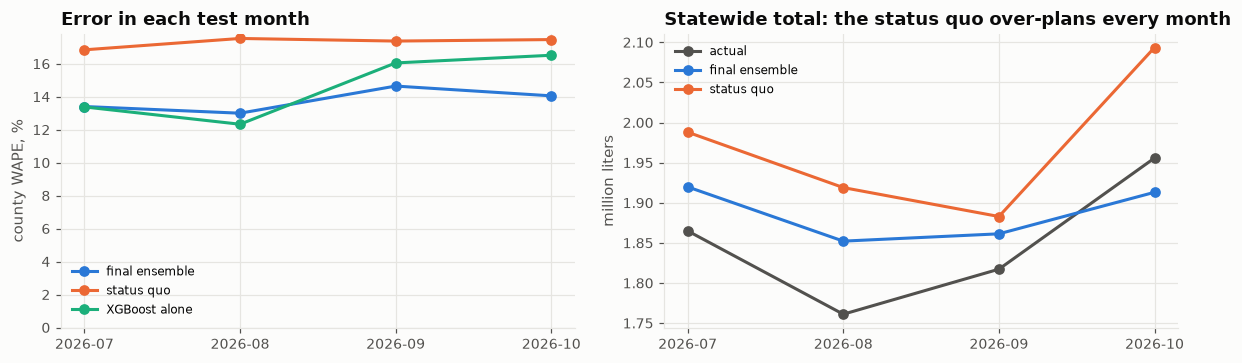

,month,final ensemble,status quo,XGBoost alone
0,2026-07,0.134,0.168,0.134
1,2026-08,0.130,0.175,0.123
2,2026-09,0.146,0.174,0.161
3,2026-10,0.141,0.175,0.165


In [10]:
from abd_demand.monitoring import monthly_error
by_month = monthly_error(predictions, {"final ensemble": "p_final", "status quo": "p_seasonal_naive_last_year",
                                       "XGBoost alone": "p_xgb"})
statewide = predictions.groupby("month")[["y", "p_final", "p_seasonal_naive_last_year"]].sum() / 1e6

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for col, color in [("final ensemble", P.BLUE), ("status quo", P.ORANGE), ("XGBoost alone", P.AQUA)]:
    axes[0].plot(by_month.month, 100 * by_month[col], marker="o", color=color, label=col)
axes[0].set_ylabel("county WAPE, %"); axes[0].set_ylim(0, None); axes[0].legend(fontsize=8)
axes[0].set_title("Error in each test month")
axes[1].plot(statewide.index, statewide.y, marker="o", color=P.INK2, label="actual")
axes[1].plot(statewide.index, statewide.p_final, marker="o", color=P.BLUE, label="final ensemble")
axes[1].plot(statewide.index, statewide.p_seasonal_naive_last_year, marker="o", color=P.ORANGE, label="status quo")
axes[1].set_ylabel("million liters"); axes[1].legend(fontsize=8)
axes[1].set_title("Statewide total: the status quo over-plans every month")
plt.tight_layout(); plt.show()
by_month

**What the errors mean.**
* **County, ~14%:** about one liter in seven is mis-planned, against one in six today, and the error is nearly
  unbiased (+2% vs +6.5%), so ABD stops systematically over-buying.
* **State, ~5%:** errors across counties cancel. This is where ABD buys from suppliers.
* **Store, ~39%:** a single store-family-month is intrinsically noisy (an order slips by a week). Use store forecasts as
  guidance, not as an order quantity.

**An honest caveat.** XGBoost alone is better at *store* level (36.6% vs 39.0%); the ensemble is better at *county* and
*state* level, where ABD plans. The API reports both.

In [11]:
predictions["size_band"] = pd.qcut(predictions.roll6_mean.fillna(0).rank(method="first"), 5,
                                   labels=["smallest 20%", "2", "3", "4", "largest 20%"])
band = predictions.groupby("size_band", observed=True)[["y", "p_xgb", "p_final", "p_seasonal_naive_last_year"]].sum()
pd.DataFrame({
    "share of liters":  band.y / band.y.sum(),
    "bias XGBoost":     band.p_xgb / band.y - 1,
    "bias final":       band.p_final / band.y - 1,
    "bias status quo":  band.p_seasonal_naive_last_year / band.y - 1,
})

,share of liters,bias XGBoost,bias final,bias status quo
size_band,,,,
smallest 20%,0.010,-0.497,0.372,1.483
2,0.010,-0.224,-0.038,0.202
3,0.038,-0.072,0.035,0.176
4,0.110,0.019,0.051,0.102
largest 20%,0.832,-0.001,0.012,0.037


The largest 20% of series carry 83% of the liters, and there the final model is almost unbiased (+1%). In the
smallest series all methods are far off in relative terms, but those series are 1% of volume.

## 7. Prediction intervals: how sure is the forecast?
> **Technique card — empirical prediction intervals and calibration.** A planner needs a range, not just a number.
> We measure, on validation data, the spread of *actual ÷ forecast* for forecasts of similar size, and take its
> 10th and 90th percentiles. That gives a P10–P90 range that should contain the actual value **80%** of the time.
> **Calibration** means checking that promise on new data: if an "80%" range contains the truth only 50% of the time,
> the intervals are over-confident.

In [12]:
calibration = pd.Series(meta["interval_calibration"])
calibration

store_coverage_p10_p90      0.861
county_coverage_p10_p90     0.775
county_coverage_below_p90   0.924
target                      0.800
dtype: float64

On the untouched test months, the county P10–P90 range contains the actual **77.5%** of the time (promise: 80%)
and 92% of actuals fall below P90 (promise: 90%). The intervals are well calibrated, so a service level built on them
means what it says.

## 8. Business value: what a better forecast is worth
**Safety stock** is the extra stock held to cover forecast error: roughly *z* × (typical error), with *z* = 1.645 for a
95% service level. A more accurate forecast needs less of it. Assumptions (stated so they can be challenged): stock valued
at ABD's 2026 cost per liter; holding cost 20% of stock value per year.

In [13]:
s26 = pd.read_parquet(C.SSOT, columns=["year", "state_bottle_cost", "sales_bottles", "liters", "mini_multipack_suspect"])
s26 = s26[(s26.year == 2026) & (s26.sales_bottles > 0) & (s26.mini_multipack_suspect == 0)]
cost_per_liter = float((s26.state_bottle_cost * s26.sales_bottles).sum() / s26.liters.sum())
del s26
Z_95 = 1.645

def safety_stock(keys, prediction_col):
    # z x RMSE of the monthly error, summed over the planning cells
    cells = predictions.groupby(keys + ["month"], observed=True)[["y", prediction_col]].sum().reset_index()
    cells["squared_error"] = (cells.y - cells[prediction_col]) ** 2
    rmse = cells.groupby(keys, observed=True).squared_error.mean() ** 0.5
    return Z_95 * rmse.sum()

rows = []
for level, keys in [("warehouse (state x family)", ["family"]), ("delivery regions (county x family)", ["county_fips_code", "family"])]:
    old, new = safety_stock(keys, "p_seasonal_naive_last_year"), safety_stock(keys, "p_final")
    rows.append({"level": level, "safety stock today (L)": old, "with forecast (L)": new,
                 "reduction": 1 - new / old, "capital freed ($)": (old - new) * cost_per_liter})
value = pd.DataFrame(rows)
value.to_csv(TABLES / "business_value.csv", index=False)

over_buying = (predictions.p_seasonal_naive_last_year.sum() - predictions.p_final.sum()) / predictions.month.nunique()
print(f"ABD cost per liter: ${cost_per_liter:.2f}")
print(f"The status quo plans {over_buying:,.0f} L/month more than the forecast (~${over_buying * cost_per_liter / 1e6:.2f}M of stock a month)")
value

ABD cost per liter: $12.25
The status quo plans 84,242 L/month more than the forecast (~$1.03M of stock a month)


,level,safety stock today (L),with forecast (L),reduction,capital freed ($)
0,warehouse (state x family),"241,433.159","181,850.514",0.247,"729,784.883"
1,delivery regions (county x family),"626,514.999","506,977.887",0.191,"1,464,123.965"


**Reading it.** At warehouse level the forecast needs about a quarter less safety stock for the same 95% service. The
bigger, more certain gain is removing the status quo's **systematic over-buying** in a shrinking market. These are
planning estimates under stated assumptions, not audited savings.

## 9. From forecast to order quantity: the newsvendor rule
> **Technique card — newsvendor model.** When you must order before demand is known, the best quantity is the
> forecast's **service-level quantile**, where
> **service level = cost of running out ÷ (cost of running out + cost of holding extra)**.
> For ABD a stock-out loses the margin (~33%) and goodwill; holding costs ~1.7% a month, so a high service level is justified.
> If stock-outs become costlier, raise the service level; if storage or capital become scarcer, lower it.
> The forecast itself does not change, only the quantile we order at.

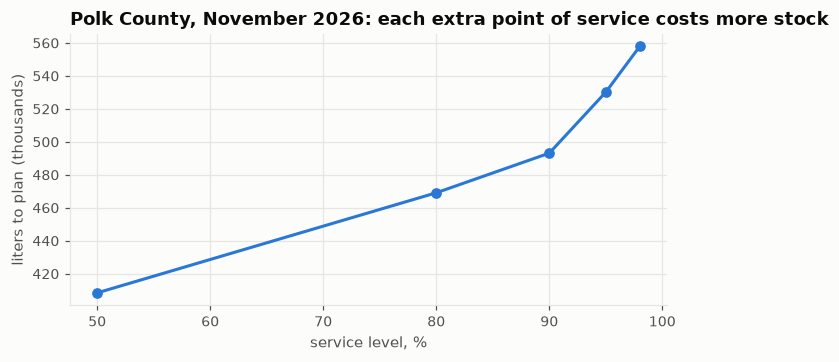

,service level,plan (L),safety stock (L)
0,0.500,"408,428.535","-7,470.815"
1,0.800,"469,135.327","53,235.977"
2,0.900,"493,180.039","77,280.689"
3,0.950,"530,203.222","114,303.872"
4,0.980,"557,908.069","142,008.719"


In [14]:
november = pd.read_parquet(C.PROCESSED / "forecast_2026_11.parquet")
polk = november[november.county_fips_code == "19153"].groupby("family", observed=True).forecast_liters.sum()  # Polk County (Des Moines)

rows = []
for service_level in [0.5, 0.8, 0.9, 0.95, 0.98]:
    plan = Fc.apply_intervals(polk.values, meta["interval_county"], service_level)
    rows.append({"service level": service_level, "plan (L)": plan.sum(), "safety stock (L)": plan.sum() - polk.sum()})
plan = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(100 * plan["service level"], plan["plan (L)"] / 1000, marker="o", color=P.BLUE)
ax.set_xlabel("service level, %"); ax.set_ylabel("liters to plan (thousands)")
ax.set_title("Polk County, November 2026: each extra point of service costs more stock")
plt.show()
plan

Going from 90% to 98% service costs a visible block of extra stock: the trade-off ABD sees in the dashboard slider (`app/`).

## 10. Surprise scenarios (decision challenge)

| Scenario | What changes | How the solution responds |
|---|---|---|
| **Budget cut** | less stock can be held | lower the service level (95% → 85%) on low-margin families first; skip tuning (section 5) |
| **Stock-outs cost more** (holidays, penalties) | higher cost of running out | raise the service level (newsvendor); the forecast is unchanged |
| **Data drift** (trend steepens, new category, another truncated month) | inputs shift | drift monitor, monthly error tracking and retrain rule (notebook 04); ETL checks stop bad data |
| **Fairness concern** (rural counties) | errors differ by group | group audit (notebook 04); ethnicity not in the model; group bias correction |
| **Missouri raises its tax** | the H1 gap shrinks | border counties recover volume; the model adapts through its lags in 1–2 months |
| **Licensing wave** | many new stores | H3: plan entrants at well under 100% net new volume; cut neighbours' plans |